# Pictogram / Isotype Chart

**Family:** Magnitude &nbsp;|&nbsp; **Library:** matplotlib / seaborn

> *Magnitude:* Compare sizes, relative or absolute (usually counts rather than rates).

## Design purpose

Represents quantities by counting repeated icons (Otto Neurath's Isotype). It turns abstract numbers into countable things for general and infographic audiences.

## When to use

- Communicate counts or ratios to a broad public ('3 in 10 people…')
- Engagement and memorability matter more than precision
- Quantities are small, whole numbers or can be rounded to units

## Avoid when

- Values need precision (fractional icons are hard to read)
- Icons are scaled by size instead of count (area distorts perception)

## Alternatives

- Waffle chart
- Bar chart

## Design tips

- One icon = a stated unit; repeat icons, never enlarge them

## Example

Average daily screen time (hours) by age group; one icon = 1 hour, synthetic data.

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

### Data

In [2]:
df = pd.DataFrame({"group": ["Teens 13–17", "Adults 18–34", "Adults 35–54", "Adults 55+"],
                   "hours": [7.5, 6.5, 5.0, 3.5]})
df

,group,hours
0,Teens 13–17,7.5
1,Adults 18–34,6.5
2,Adults 35–54,5.0
3,Adults 55+,3.5


### Plot

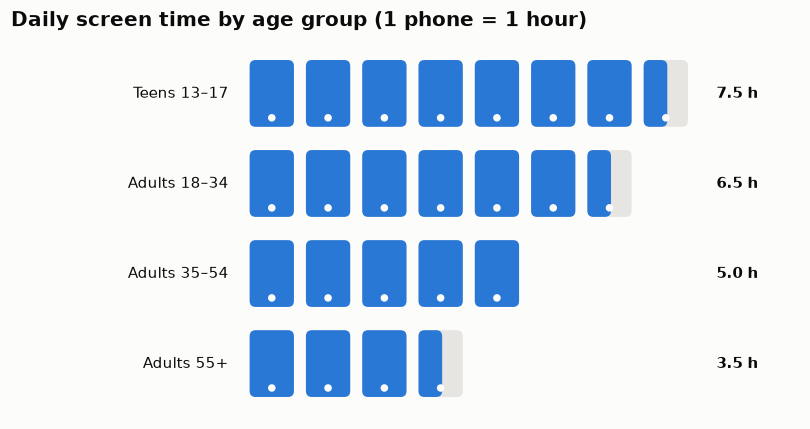

In [3]:
from matplotlib.patches import FancyBboxPatch
def phone(ax, x, y, frac=1.0, color=PALETTE[0]):
    w, h = 0.55, 0.85
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02,rounding_size=0.08",
                                facecolor="#e6e5e1", edgecolor="none"))
    ax.add_patch(FancyBboxPatch((x, y), w * frac, h,
                                boxstyle="round,pad=0.02,rounding_size=0.08",
                                facecolor=color, edgecolor="none"))
    ax.add_patch(plt.Circle((x + w / 2, y + 0.1), 0.04, color="#fcfcfb"))
fig, ax = plt.subplots(figsize=(9, 4))
for row, (_, r) in enumerate(df.iloc[::-1].iterrows()):
    full, part = int(r["hours"]), r["hours"] % 1
    for k in range(full):
        phone(ax, k * 0.75, row * 1.2)
    if part:
        phone(ax, full * 0.75, row * 1.2, frac=part)
    ax.text(-0.3, row * 1.2 + 0.42, r["group"], ha="right", va="center", fontsize=10)
    ax.text(8 * 0.75 + 0.2, row * 1.2 + 0.42, f"{r['hours']:.1f} h", va="center",
            fontweight="bold")
ax.set_xlim(-3.2, 7.3)
ax.set_ylim(-0.3, len(df) * 1.2)
ax.set_aspect("equal")
ax.axis("off")
ax.set_title("Daily screen time by age group (1 phone = 1 hour)")
fig.tight_layout()
plt.show()

---
Standalone script: [`pictogram_isotype.py`](pictogram_isotype.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)